<a href="https://colab.research.google.com/github/luckyKumar37/Deep_learning_project/blob/main/cats_vs_dogs_identifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import os
import random
import numpy as np
import tensorflow as tf

def set_reproducibility(seed=42):
    # 1. Set Python core random seed
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)

    # 2. Set NumPy random seed
    np.random.seed(seed)

    # 3. Set TensorFlow global random seed
    tf.random.set_seed(seed)

    # 4. Force TensorFlow to use deterministic operations (where available)
    os.environ['TF_DETERMINISTIC_OPS'] = '1'
    os.environ['TF_CUDNN_DETERMINISTIC'] = '1'

# Run the function to lock down seeds
set_reproducibility(42)


In [11]:
!pip install opendatasets --quiet
import opendatasets as od

# Provide the full Kaggle dataset URL
od.download("https://www.kaggle.com/datasets/salader/dogsvscats")

Skipping, found downloaded files in "./dogsvscats" (use force=True to force download)


In [12]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Dropout

In [13]:
train_data = tf.keras.utils.image_dataset_from_directory(
    directory = '/content/dogsvscats/train',
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 32,
    image_size = (256, 256),
    seed = 42
)

test_data = tf.keras.utils.image_dataset_from_directory(
    directory = '/content/dogsvscats/test',
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 32,
    image_size = (256, 256),
    seed = 42
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [14]:

def process_image(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image,label

train_data = train_data.map(process_image)
test_data = test_data.map(process_image)

In [15]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomContrast(0.2)
])





In [16]:
initializer = tf.keras.initializers.he_uniform()

model = Sequential([
    tf.keras.layers.InputLayer(input_shape=(256, 256, 3)),
    data_augmentation,
    Conv2D(32, (3, 3), activation='relu',kernel_initializer=initializer),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation='relu',kernel_initializer=initializer),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Conv2D(128, (3, 3), activation='relu',kernel_initializer=initializer),
    BatchNormalization(),
    MaxPooling2D(2,2),
    Conv2D(256, (3, 3), activation='relu',kernel_initializer=initializer),
    BatchNormalization(),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu',kernel_initializer=initializer),
    Dropout(0.3),
    Dense(64, activation='relu',kernel_initializer=initializer),
    Dropout(0.3),
    Dense(1, activation='sigmoid')

])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,821,313 (26.02 MB)

 Trainable params: 6,820,353 (26.02 MB)

 Non-trainable params: 960 (3.75 KB)

In [18]:
call_back = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(filepath='best_model.keras', save_best_only=True,monitor='val_accuracy')
]


In [19]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [20]:
histroy = model.fit(train_data, epochs=10, validation_data=test_data,callbacks=call_back)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 116s 180ms/step - accuracy: 0.5541 - loss: 1.2330 - val_accuracy: 0.6208 - val_loss: 0.6543
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 116s 186ms/step - accuracy: 0.6434 - loss: 0.6382 - val_accuracy: 0.7046 - val_loss: 0.5718
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 120s 191ms/step - accuracy: 0.6964 - loss: 0.5838 - val_accuracy: 0.7194 - val_loss: 0.5479
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 120s 192ms/step - accuracy: 0.7206 - loss: 0.5567 - val_accuracy: 0.7320 - val_loss: 0.5300
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 117s 187ms/step - accuracy: 0.7536 - loss: 0.5107 - val_accuracy: 0.6094 - val_loss: 0.9467
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 117s 187ms/step - accuracy: 0.7907 - loss: 0.4537 - val_accuracy: 0.7024 - val_loss: 0.9463
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 117s 187ms/step - accuracy: 0.8231 - loss: 0.4015 - val_accuracy: 0.8676 - val_loss: 0.3392
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 117s 187ms/step - accuracy: 0.8464 -

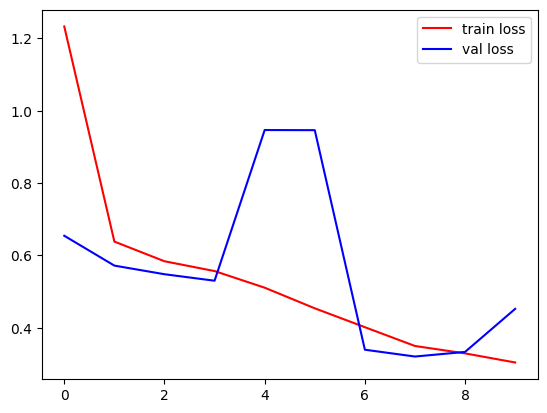

In [21]:
import matplotlib.pyplot as plt

plt.plot(histroy.history['loss'],color='red',label='train loss')
plt.plot(histroy.history['val_loss'],color='blue',label='val loss')
plt.legend()
plt.show()

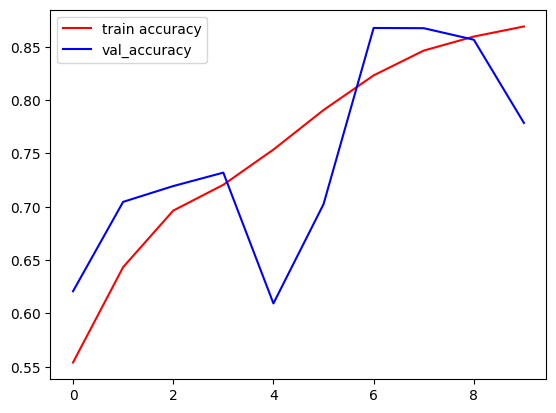

In [22]:
plt.plot(histroy.history['accuracy'],color='red',label='train accuracy')
plt.plot(histroy.history['val_accuracy'],color='blue',label='val_accuracy')
plt.legend()
plt.show()